
# Bank Loan & Credit Risk Analytics

## 1. Domain
**Banking & Financial Services | Credit Risk Management | Financial Data Analytics**

## 2. Project Objective
- Analyze customer financial profiles and loan characteristics.
- Identify loan default patterns across different borrower segments.
- Examine the impact of income, employment history, interest rates, and loan grades on credit risk.
- Investigate relationships between loan amounts, loan purposes, and repayment status.
- Identify high-risk borrower categories through exploratory data analysis.
- Provide data-driven insights to support better lending decisions and credit risk management.

## 3. Dataset Information
- **Dataset Name:** Credit Risk Dataset
- **Source:** Kaggle
- **Dataset Link:** https://www.kaggle.com/datasets/laotse/credit-risk-dataset
- **File Name:** `credit_risk_dataset.csv`
- **File Format:** CSV
- **Total Records:** 32,581
- **Total Columns:** 12
- **Target Variable:** `loan_status`

## 4. Tools & Technologies
    1. Python.
    2. Pandas.
    3. Numpy.
    4. Data Cleaning & Preprocessing.
    5. Missing Value Treatment.
    6. Exploratory Data Analysis(EDA).
    7. Data Visulization (Matplotlib & Seaborn).


# Step 1: Data Loading and Data Understanding

- Import Libraries

In [1]:
import numpy as np
import pandas as pd

- Load Dataset

In [2]:
df=pd.read_csv('credit_risk_dataset.csv',encoding='latin1')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


- Check total number of records (rows) and attributes (columns)

In [3]:
print("Total Rows:",df.shape[0])
print("Total Columns:",df.shape[1])

Total Rows: 32581
Total Columns: 12


- Display Columns

In [4]:
df.columns.to_list()

['person_age',
 'person_income',
 'person_home_ownership',
 'person_emp_length',
 'loan_intent',
 'loan_grade',
 'loan_amnt',
 'loan_int_rate',
 'loan_status',
 'loan_percent_income',
 'cb_person_default_on_file',
 'cb_person_cred_hist_length']

- Display data type of each column and dataset information

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


- Generate Statistical Summary

In [6]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


- Identify categorical and numerical columns

In [7]:
cat_cols= df.select_dtypes(include=['object']).columns.to_list()
cat_cols

['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file']

In [8]:
num_cols= df.select_dtypes(exclude=['object']).columns.to_list()
num_cols

['person_age',
 'person_income',
 'person_emp_length',
 'loan_amnt',
 'loan_int_rate',
 'loan_status',
 'loan_percent_income',
 'cb_person_cred_hist_length']

- Understand the Target Variable

In [9]:
print(df['loan_status'].value_counts())

loan_status
0    25473
1     7108
Name: count, dtype: int64



### Key Findings:

1. The original dataset contains **32,581 records and 12 columns**.
2. The dataset includes both numerical and categorical features such as customer age, annual income, employment length, loan amount, interest rate, loan grade, and loan purpose.
3. The target variable, `loan_status`, classifies borrowers into:
   - **0:** Non-defaulted loans
   - **1:** Defaulted loans

# Ste 2: Data Cleaning and Preprocessing

- Identify Missing Values

In [10]:
missing_val=df.isnull().sum()
print(missing_val[missing_val > 0])

person_emp_length     895
loan_int_rate        3116
dtype: int64


- **Missing Values:**
    1. person_emp_length
    2. loan_int_rate

### Missing Data Treatment

In [11]:
# Misiing columns both are numerical columns so mean method is appropriate
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].mean())
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].mean())

In [12]:
print('Missing values after cleaning:\n',df.isnull().sum().sum())

Missing values after cleaning:
 0


### Check Duplicate Records

In [13]:
duplicates = df.duplicated().sum()
print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 165


### Remove Duplicate Records

In [14]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

In [15]:
print("Duplicate Rows After Cleaning:",df.duplicated().sum())
print("Dataset Shape:", df.shape)

Duplicate Rows After Cleaning: 0
Dataset Shape: (32416, 12)


- To identify unrealistic attributes

In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32416.0,27.747008,6.354100,20.00,23.00,26.000000,30.00,144.00
person_income,32416.0,66091.640826,62015.580269,4000.00,38542.00,55000.000000,79218.00,6000000.00
person_emp_length,32416.0,4.790488,4.088378,0.00,2.00,4.000000,7.00,123.00
loan_amnt,32416.0,9593.845632,6322.730241,500.00,5000.00,8000.000000,12250.00,35000.00
loan_int_rate,32416.0,11.016733,3.083040,5.42,8.49,11.011695,13.11,23.22
loan_status,32416.0,0.218688,0.413363,0.00,0.00,0.000000,0.00,1.00
loan_percent_income,32416.0,0.170250,0.106812,0.00,0.09,0.150000,0.23,0.83
cb_person_cred_hist_length,32416.0,5.811297,4.059030,2.00,3.00,4.000000,8.00,30.00


In [17]:
#Identify unrealistic ages
invalid_age=~df['person_age'].between(18, 100)
print("Unrealistic Age Records:", invalid_age.sum())

# Identify unrealistic employment length
invalid_emp=((df['person_emp_length'] < 0) | (df['person_emp_length'] > df['person_age'] - 18))  #considering a person starts working from age 18
print("Unrealistic Employment Records:",invalid_emp.sum())

Unrealistic Age Records: 5
Unrealistic Employment Records: 7944


In [18]:
# Replace unrealistic ages and employment length with NaN
df.loc[invalid_age, 'person_age'] = np.nan
df.loc[invalid_emp, 'person_emp_length'] = np.nan

In [19]:
missing_val=df.isnull().sum()
print(missing_val[missing_val > 0])

person_age              5
person_emp_length    7944
dtype: int64


In [20]:
# Handling these NaN values 
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].mean())
df['person_age'] = df['person_age'].fillna(df['person_age'].mean())

In [21]:
print('Missing values after cleaning:\n',df.isnull().sum().sum())

Missing values after cleaning:
 0


### Validate Loan and Income Values

In [22]:
print("Invalid Income:",(df['person_income'] <= 0).sum())
print("Invalid Loan Amount:",(df['loan_amnt'] <= 0).sum())
print("Invalid Interest Rate:",(df['loan_int_rate'] <= 0).sum())
print("Invalid Loan Status:",(~df['loan_status'].isin([0, 1])).sum())

Invalid Income: 0
Invalid Loan Amount: 0
Invalid Interest Rate: 0
Invalid Loan Status: 0


- No Invalid income, loan amount, interest rate, loan status observed.


### Key Findings:

1. Missing values in `person_emp_length` and `loan_int_rate` were handled using mean imputation to preserve borrower records.

2. A total of **165 exact duplicate records** were identified and removed.

3. Numerical data types were standardized, and invalid financial values were checked.

4. Unrealistic borrower ages and employment lengths were identified and handled using defined validation rules

# Step 3 :Exploratory Data Analysis (EDA)

- Import visualization libarary

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

### Q1. What percentage of bank loans have defaulted?

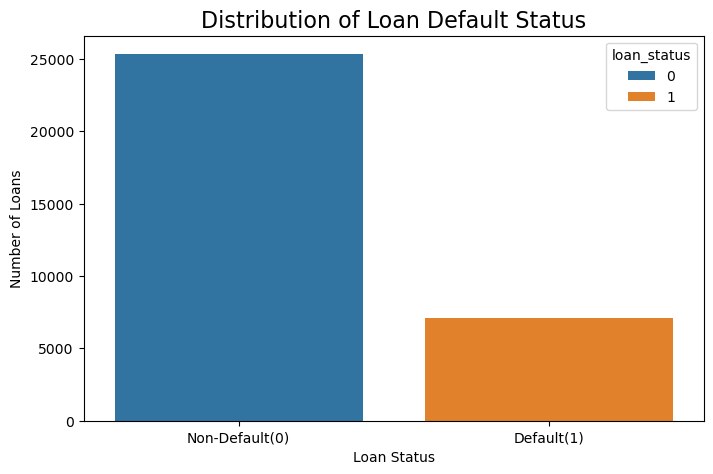

In [24]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='loan_status',
    hue='loan_status',
    legend=True
)
plt.title('Distribution of Loan Default Status', fontsize=16)
plt.xlabel('Loan Status')
plt.ylabel('Number of Loans')
plt.xticks([0, 1], ['Non-Default(0)', 'Default(1)'])
plt.show()

### Observation: 
- The count plot compares defaulted and non-defaulted loans. The calculated default rate shows the percentage of loans that defaulted in the dataset.

### Conclusion: 
- The default rate provides a baseline for understanding the dataset's credit risk.
- Banks can use default-rate monitoring to identify portfolio deterioration and evaluate whether additional risk controls are needed.

### Q2. How are loan amounts distributed among borrowers?

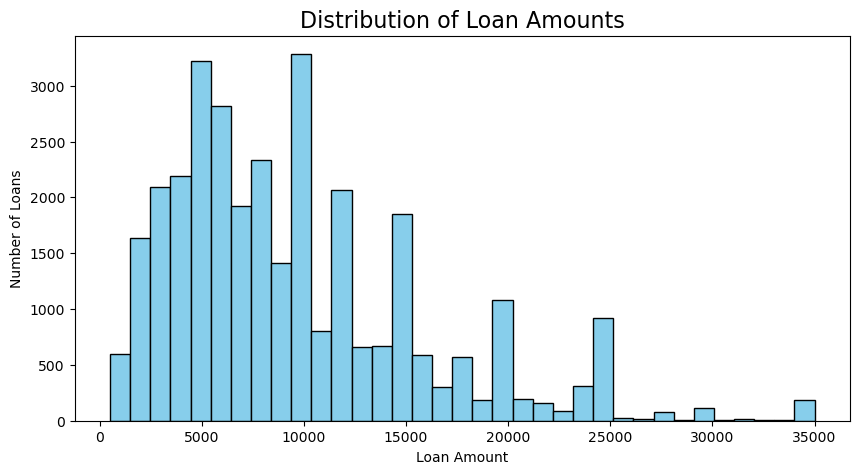

In [25]:
plt.figure(figsize=(10, 5))
plt.hist(
    data=df,
    x='loan_amnt',
    bins=35,
    color='skyblue',
    edgecolor='black'
)
plt.title('Distribution of Loan Amounts', fontsize=16)
plt.xlabel('Loan Amount')
plt.ylabel('Number of Loans')
plt.show()

### Observation:
- Most loan amounts are concentrated between 2,000 and 15,000, with the highest frequencies around 4,000–5,000 and 9,000–10,000 (approximately 3,200 loans per peak bin).
- The distribution is right-skewed.
### Conclusion:
- Small and medium-sized loans dominate the portfolio, indicating higher demand for lower loan amounts.

### Q3. How does borrower income differ between defaulted and non-defaulted loans?

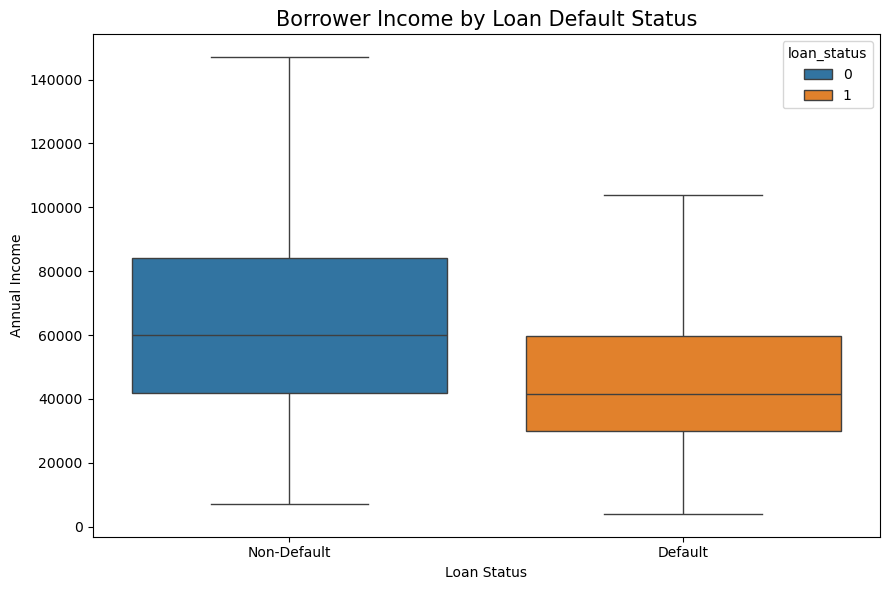

In [26]:
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df,
    x='loan_status',
    y='person_income',
    hue='loan_status',
    legend=True,
    showfliers=False
)
plt.title('Borrower Income by Loan Default Status', fontsize=15)
plt.xlabel('Loan Status')
plt.ylabel('Annual Income')
plt.xticks([0, 1], ['Non-Default', 'Default'])
plt.tight_layout()
plt.show()

### Observation:
- Non-default borrowers (0) have a higher median annual income compared to default borrowers (1).
### Conclusion:
- Lower annual income is associated with higher loan default risk, suggesting that income is an important factor in credit risk assessment.
- Banks should evaluate borrowers' income stability and repayment capacity before approving loans to minimize potential defaults.

### Q4. Which loan grades have the highest default rates?


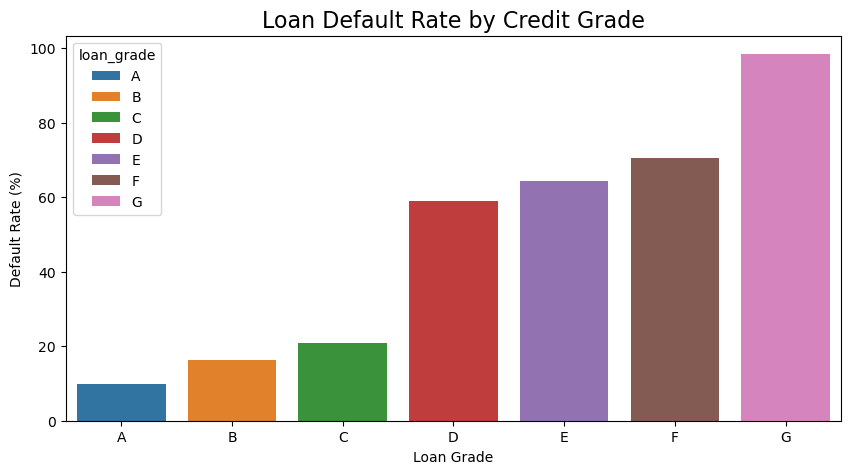

In [27]:
grade_risk =df.groupby('loan_grade')['loan_status'].agg(['mean'])
grade_risk['Default Rate'] = grade_risk['mean'] * 100

plt.figure(figsize=(10, 5))
sns.barplot(
    data=grade_risk,
    x='loan_grade',
    y='Default Rate',
    hue='loan_grade',
    legend=True
)
plt.title('Loan Default Rate by Credit Grade', fontsize=16)
plt.xlabel('Loan Grade')
plt.ylabel('Default Rate (%)')
plt.show()

### Observation:
- Grade A has the lowest default rate, followed by Grade B and Grade C.
- Default rates increase significantly for Grade D , E, F, and G , indicating a strong relationship between credit grade and loan default.
### Conclusion:
- Credit grade is a strong indicator of loan default risk, with lower credit grades showing substantially higher default rates.
- Banks should prioritize Grades A–C for lower-risk lending and apply stricter credit assessments and risk controls for Grades D–G to minimize financial losses.

### Q5. How do interest rates vary between defaulted and non-defaulted loans?

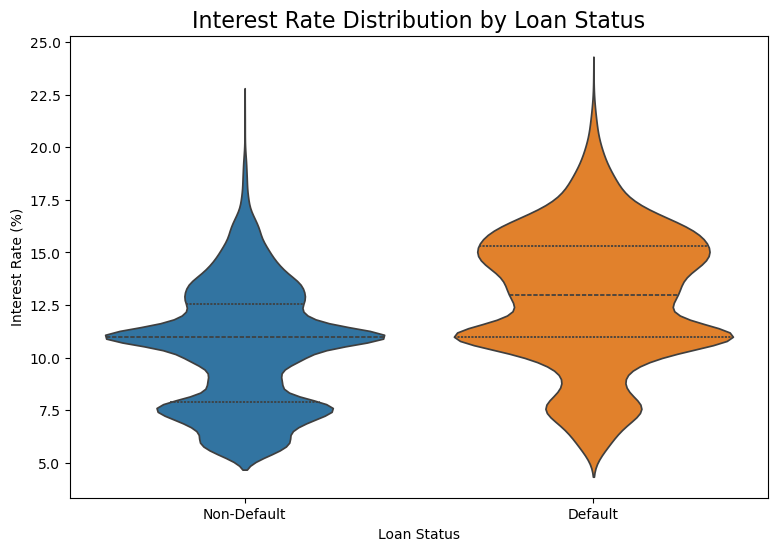

In [28]:
plt.figure(figsize=(9, 6))
sns.violinplot(
    data=df,
    x='loan_status',
    y='loan_int_rate',
    hue='loan_status',
    legend=False,
    inner='quartile'
)
plt.title('Interest Rate Distribution by Loan Status',fontsize=16)
plt.xlabel('Loan Status')
plt.ylabel('Interest Rate (%)')
plt.xticks([0, 1], ['Non-Default', 'Default'])
plt.show()

### Observation:
- Non-default borrowers have a median interest rate of approximately 11%, with most rates concentrated between 8% and 13%.
- Default borrowers have a higher median interest rate of approximately 13.5%, with significant concentrations around 12% and 16%.
### Conclusion:
- Higher interest rates are associated with increased loan default risk, indicating that interest rate is an important factor in credit risk analysis.
- Banks should carefully assess borrowers' repayment capacity and interest rate affordability to reduce defaults and improve loan recovery.

### Q6. Which loan purposes have the highest default rates?

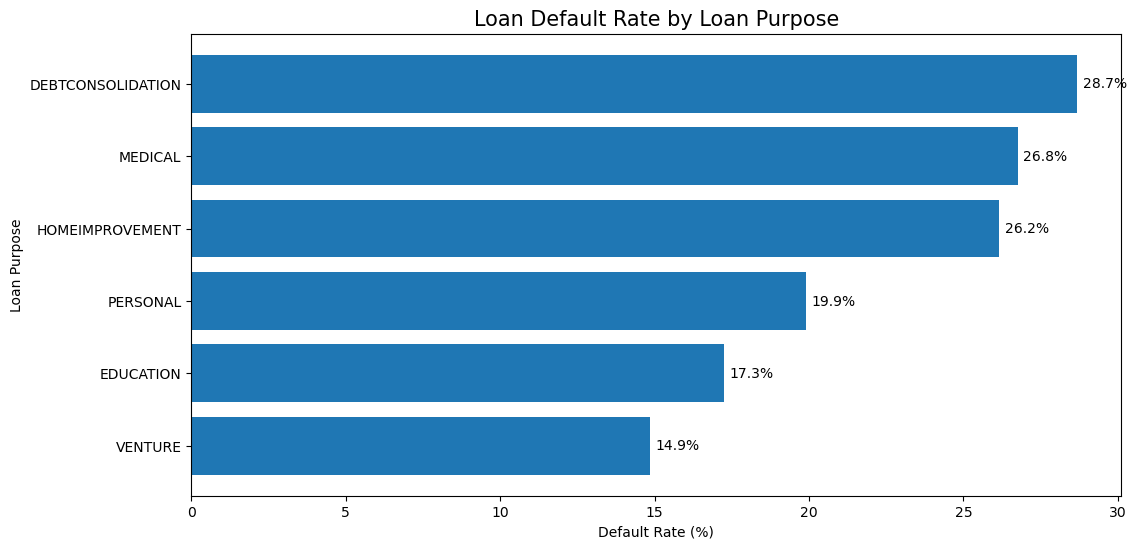

,loan_intent,Default_Rate,Total_Loans
5,VENTURE,14.853925,5682
1,EDUCATION,17.251599,6411
4,PERSONAL,19.898145,5498
2,HOMEIMPROVEMENT,26.154702,3594
3,MEDICAL,26.762661,6042
0,DEBTCONSOLIDATION,28.676045,5189


In [29]:
purpose_risk=df.groupby('loan_intent')['loan_status'].agg(Default_Rate='mean', Total_Loans='count').reset_index()
purpose_risk['Default_Rate'] *= 100
purpose_risk=purpose_risk.sort_values('Default_Rate')

plt.figure(figsize=(12, 6))
bars= plt.barh(
    purpose_risk['loan_intent'],
    purpose_risk['Default_Rate']
)
plt.bar_label(bars, fmt='%.1f%%', padding=4)
plt.title('Loan Default Rate by Loan Purpose', fontsize=15)
plt.xlabel('Default Rate (%)')
plt.ylabel('Loan Purpose')
plt.show()
display(purpose_risk)

### Observation:
- Debt consolidation has the highest default rate at 28.7%, followed by Medical (26.8%) and Home Improvement (26.2%).
- Venture loans have the lowest default rate at 14.9%, followed by Education (17.3%) and Personal (19.9%).
### Conclusion:
- Loan purpose is an important factor in credit risk assessment, with debt consolidation, medical, and home improvement loans showing higher default risk.
- Banks should apply stricter repayment capacity assessments for high-risk loan purposes and consider loan purpose when developing lending strategies to minimize defaults.

### Q7. What is the relationship between loan-to-income ratio and loan default risk?

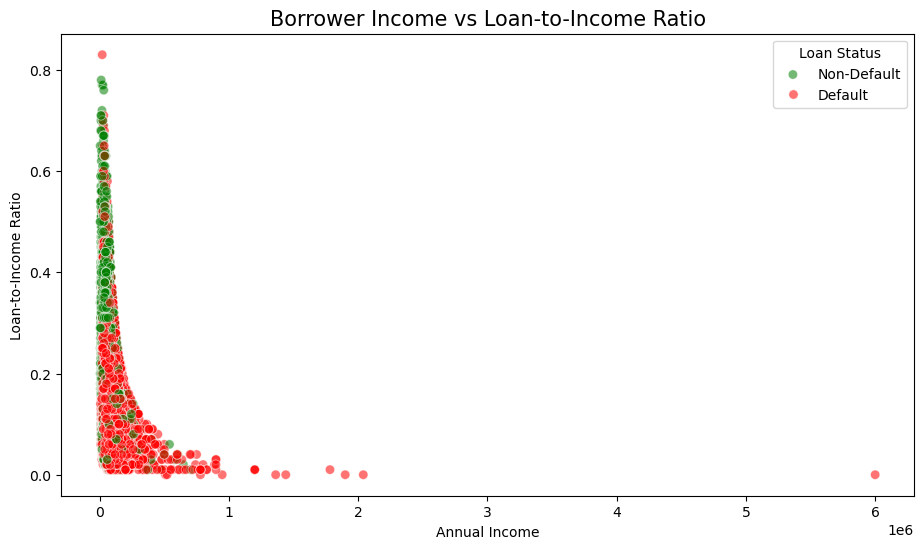

In [30]:
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df,
    x='person_income',
    y='loan_percent_income',
    hue='loan_status',
    palette={0: 'red', 1: 'green'},
    alpha=0.55,
    s=45
)
plt.title('Borrower Income vs Loan-to-Income Ratio',fontsize=15)
plt.xlabel('Annual Income')
plt.ylabel('Loan-to-Income Ratio')
plt.legend(title='Loan Status',labels=['Non-Default', 'Default'])
plt.show()

### Observation:
- Lower-income borrowers show higher loan-to-income ratios, reaching approximately 0.8 (80%), while higher-income borrowers generally have ratios below 0.1 (10%).
- Both default and non-default cases appear at higher ratios, while income outliers extend up to approximately 6 million.
### Conclusion:
- Loan-to-income ratio decreases as borrower income increases, indicating a lower relative debt burden for higher-income borrowers.
- Banks should assess loan-to-income ratios alongside income and repayment capacity to identify financially vulnerable borrowers and manage credit risk effectively.

### Q8. Which numerical factors are most strongly correlated with loan defaults?

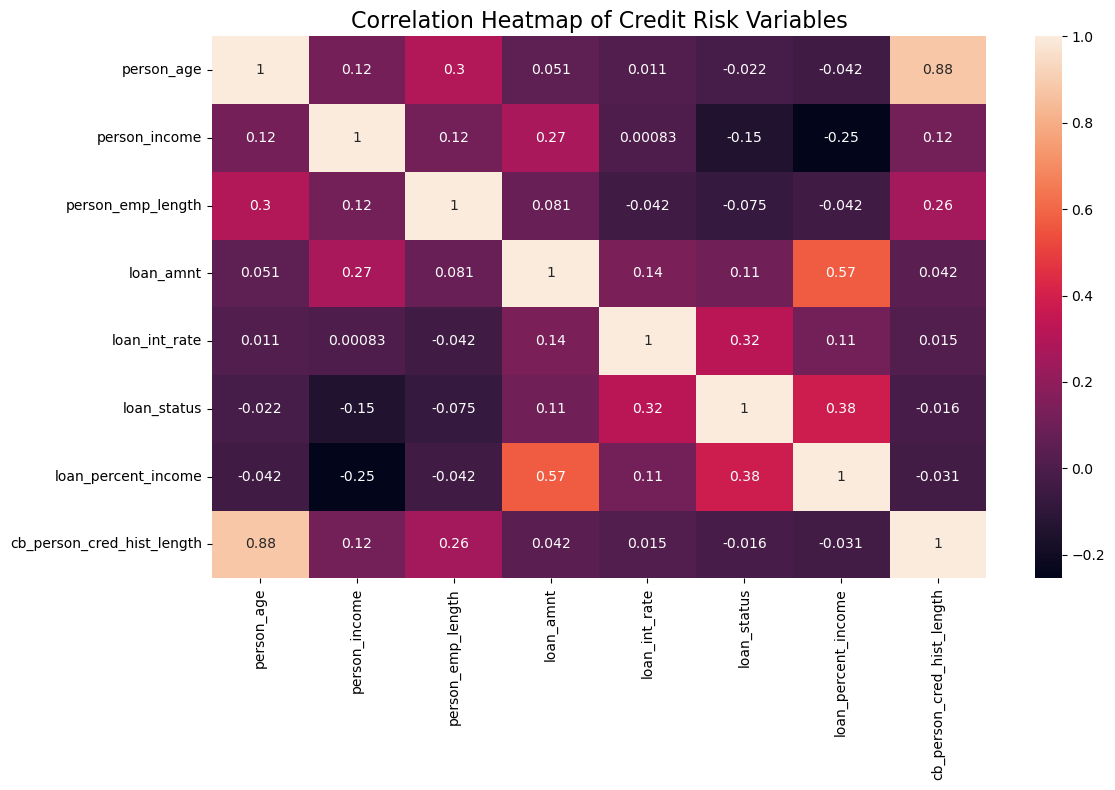

In [31]:
num_cols_corr=df.select_dtypes(exclude='object').corr()
plt.figure(figsize=(12, 8))
sns.heatmap(num_cols_corr,annot=True)
plt.title('Correlation Heatmap of Credit Risk Variables',fontsize=16)
plt.tight_layout()
plt.show()

### Observation:
- Loan-to-income ratio (0.38) and interest rate (0.32) show the strongest positive correlations with loan default (loan_status).
- Annual income (-0.15) has a negative correlation with default, while age (-0.022) and employment length (-0.075) show very weak relationships.
- Age and credit history length (0.88) have the strongest overall correlation, followed by loan amount and loan-to-income ratio (0.57).
### Conclusion:
- Loan-to-income ratio and interest rate are the strongest numerical indicators of loan default risk in this heatmap.
- Banks should prioritize repayment capacity, interest rates, and borrower income during credit risk assessment to support better lending decisions and reduce potential defaults.

# Step 4: Data Visualization Dashboard


###  Key Findings:

1. **Loan-to-Income Ratio:** An important indicator of financial burden, helping assess potential loan default risk.

2. **Loan Grade:** Helps distinguish borrowers across different credit risk categories and identify higher-risk loan segments.

3. **Interest Rate:** An important lending factor that may be associated with borrower creditworthiness and loan default risk.

4. **Borrower Income & Employment:** Provide useful insights into financial stability and repayment capacity.

5. **Credit History:** Previous loan defaults can help identify borrowers requiring closer credit risk assessment.

##  Final Conclusion:

- This project successfully transformed raw banking data into clean, structured, and insight-driven credit risk analytics.

- **Loan-to-income ratio, loan grade, and interest rate** emerged as key factors to investigate when evaluating loan default risk, alongside borrower income and credit history.

- Overall, this analysis provides valuable insights to help banks and financial institutions **improve credit risk assessment, identify high-risk borrower segments, minimize potential loan losses, and make informed lending decisions**.
